# 6 — Random forest


## Imports


In [1]:
from pathlib import Path
import hashlib
import shutil
import importlib.metadata
import json
import platform
import gc
import random
from time import perf_counter
import joblib
import numpy as np
import optuna
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

from sklearn.model_selection import train_test_split


c:\Users\Kongkiat\miniconda3\envs\pattern\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration


In [2]:
from pathlib import Path
# ใช้ project root เดียวกัน ไม่ต้อง import โค้ด pipeline จาก program
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'dataset').is_dir() and (p / 'model').is_dir() and (p / 'program').is_dir())
RAW = ROOT / 'dataset/raw/mit-bih-arrhythmia-database-1.0.0'
DATA = ROOT / 'dataset/processed'
ARTIFACTS = ROOT / 'model/artifacts'
REPORTS = ROOT / 'model/reports'
CLASSES = ['N', 'S', 'V', 'F', 'Q']
SYMBOLS = ['NLRej', 'AaJS', 'VE', 'F', '/fQ']
LABEL_MAP = {s: i for i, group in enumerate(SYMBOLS) for s in group}
SEED = 42
PREPROCESSING = {'version': 1, 'fs': 360, 'left': 90, 'right': 162,
                 'band': [0.5, 40], 'order': 4, 'leads': ['MLII', 'V5']}
MODEL = 'rf'


## Baseline hyperparameters


In [3]:
# ค่าตั้งต้นสำหรับ baseline แก้เฉพาะ cell นี้ได้
BASELINE_PARAMETERS = {
    'n_estimators': 300,
    'max_depth': None,
    'min_samples_leaf': 1,
    'max_features': 'sqrt',
}


## Tuning hyperparameters


In [4]:
TRIALS = 10
# จำนวน trials ต่อ weighted/unweighted และช่วงค้นหา
TUNING_SPACE = {
    'n_estimators': {'type': 'categorical', 'choices': [300, 600]},
    'max_depth': {'type': 'categorical', 'choices': [None, 15, 30]},
    'min_samples_leaf': {'type': 'categorical', 'choices': [1, 2, 5]},
    'max_features': {'type': 'categorical', 'choices': ['sqrt', 0.5]},
}


## Training controls


In [5]:
WEIGHTING_OPTIONS = [False, True]


## Artifact helpers


In [6]:
def read_json(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'ไม่พบ {path}; กรุณารัน notebook ขั้นก่อนหน้าก่อน')
    return json.loads(path.read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def reset_directory(path):
    # ล้างเฉพาะโฟลเดอร์ผลลัพธ์ย่อย ห้ามลบ project root หรือโฟลเดอร์รวม
    path = Path(path).resolve()
    roots = [DATA.resolve(), ARTIFACTS.resolve(), REPORTS.resolve()]
    if not any(path != root and path.is_relative_to(root) for root in roots):
        raise ValueError(f'ไม่ใช่โฟลเดอร์ผลลัพธ์ย่อย: {path}')
    if path.is_dir():
        shutil.rmtree(path)
    elif path.exists():
        path.unlink()
    path.mkdir(parents=True, exist_ok=True)
    return path


## Load partition helper


In [7]:
def load_partition(split, *, allow_test=False):
    if split not in ['train', 'validation', 'test']:
        raise ValueError('Unknown partition')
    if split == 'test' and not allow_test:
        raise PermissionError('Test เปิดใน notebook 11 สำหรับประเมินและเลือกผู้ชนะ')
    manifest = read_json(DATA / 'prepared.json')
    folder = DATA / split
    for name in ['metadata.parquet', 'waveforms.npy', 'features.npy']:
        if sha256(folder / name) != manifest['files'][f'{split}/{name}']:
            raise ValueError(f'artifact เปลี่ยน: {split}/{name}')
    meta = pd.read_parquet(folder / 'metadata.parquet')
    waves, x = np.load(folder / 'waveforms.npy'), np.load(folder / 'features.npy')
    if len(meta) != len(waves) or len(meta) != len(x) or meta.beat_id.duplicated().any():
        raise ValueError('beat alignment ไม่ถูกต้อง')
    if not meta.split.eq(split).all() or set(meta.class_id) != set(range(5)):
        raise ValueError('partition หรือ class coverage ไม่ถูกต้อง')
    if not np.array_equal(meta.waveform_index.to_numpy(), np.arange(len(meta))):
        raise ValueError('waveform index ไม่ตรงกับ metadata')
    if waves.shape != (len(meta), 252) or not np.isfinite(waves).all() or not np.isfinite(x).all():
        raise ValueError('ขนาด waveform หรือค่าข้อมูลหลัง preprocessing ไม่ถูกต้อง')
    return {'meta': meta, 'wave': waves, 'x': x, 'y': meta.class_id.to_numpy()}

## Metrics and training weights


In [8]:
def macro_f1(y, predicted):
    return float(f1_score(y, predicted, labels=list(range(5)), average='macro', zero_division=0))

def weights_from_train(y):
    counts = np.bincount(y, minlength=5)
    if (counts == 0).any():
        raise ValueError('Train ต้องมีครบ 5 คลาส')
    return len(y) / (5 * counts)

## Reproducibility


In [9]:
def environment():
    packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'wfdb', 'xgboost',
                'torch', 'optuna', 'streamlit', 'pyarrow']
    versions = {}
    for package in packages:
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            versions[package] = 'not installed'
    return {'python': platform.python_version(), 'platform': platform.platform(),
            'processor': platform.processor(), 'packages': versions}

def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

## Prediction


In [10]:
def probabilities(model, kind, values, device='cpu', batch_size=128):
    output = np.zeros((len(values), 5), dtype=np.float32)
    output[:, np.asarray(model.classes_, dtype=int)] = model.predict_proba(values)
    return output

def synchronize(device):
    if str(device).startswith('cuda'):
        torch.cuda.synchronize()

## Fit and save one candidate


In [11]:
# Train เท่านั้นที่ปรับน้ำหนักโมเดล; Validation ใช้ให้คะแนนและเลือก checkpoint
def fit_candidate(kind, weighted, parameters, folder, train, validation, *, epochs=None, rounds=None):
    reset_directory(folder)
    set_seed()
    is_dl = False
    device = 'cuda' if is_dl and torch.cuda.is_available() else 'cpu'
    if is_dl and device != 'cuda':
        raise RuntimeError('แผนนี้ใช้ GPU สำหรับ DL: ติดตั้ง PyTorch CUDA ก่อนรัน')
    weights = weights_from_train(train['y']) if weighted else None
    started = perf_counter()
    history, best_round, used_batch, oom_batches = ({}, None, None, [])
    model = RandomForestClassifier(**parameters, random_state=SEED, n_jobs=-1, class_weight=None if weights is None else dict(enumerate(weights)))
    model.fit(train['x'], train['y'])
    joblib.dump(model, folder / 'model.joblib')
    synchronize(device)
    train_seconds = perf_counter() - started
    values = validation['wave'] if is_dl else validation['x']
    proba = probabilities(model, kind, values, device)
    score = macro_f1(validation['y'], proba.argmax(1))
    result = validation['meta'].copy()
    result['predicted'] = proba.argmax(1)
    for i in range(5):
        result[f'score_{i}'] = proba[:, i]
    result.to_parquet(folder / 'validation_predictions.parquet', index=False)
    info = {'kind': kind, 'weighted': weighted, 'seed': SEED, 'parameters': parameters, 'validation_macro_f1': score, 'train_seconds': train_seconds, 'best_epoch_or_round': best_round, 'batch_size': used_batch, 'oom_batch_attempts': oom_batches, 'device': device, 'gpu': torch.cuda.get_device_name(0) if device == 'cuda' else None, 'class_weights': None if weights is None else weights.tolist(), 'prepared_hash': sha256(DATA / 'prepared.json'), 'environment': environment()}
    write_json(folder / 'info.json', info)
    del model
    gc.collect()
    if device == 'cuda':
        torch.cuda.empty_cache()
    return info

## Hyperparameter search space


In [12]:
def search_parameters(trial, kind):
    # ช่วงค้นหาทั้งหมดแก้ได้ใน cell Tuning hyperparameters ด้านบน
    values = {}
    for name, spec in TUNING_SPACE.items():
        if spec['type'] == 'categorical':
            values[name] = trial.suggest_categorical(name, spec['choices'])
        elif spec['type'] == 'float':
            values[name] = trial.suggest_float(name, spec['low'], spec['high'],
                                               log=spec.get('log', False))
        else:
            raise ValueError(f'Unknown parameter type: {spec["type"]}')
    if kind in ['cnn', 'cnn_bilstm']:
        values['channels'] = list(CHANNEL_OPTIONS[values.pop('width')])
    return values


## Load Train and Validation


In [13]:
# ไม่อ่าน Test และไม่แบ่ง inner validation
train = load_partition('train')
validation = load_partition('validation')

## Baseline


In [14]:
# ฝึก baseline ก่อน เพื่อเทียบกับผล tuning โดยใช้ split เดียวกัน
runs = {}
for weighted in WEIGHTING_OPTIONS:
    name = f'{MODEL}_{"weighted" if weighted else "unweighted"}'
    folder = ARTIFACTS / name
    reset_directory(folder)
    baseline = fit_candidate(MODEL, weighted, BASELINE_PARAMETERS, folder / 'baseline', train, validation)
    runs[name] = {'folder': folder, 'weighted': weighted, 'baseline': baseline,
                  'candidates': [('baseline', baseline)], 'tuning_seconds': 0.}

## Tuning on Validation


In [15]:
# แต่ละ trial ฝึกด้วย hyperparameters ของ trial โดยใช้ seed 42 เดียวกัน
# หลัง tuning เลือก checkpoint ที่มีแล้ว ไม่ฝึกใหม่อีกครั้ง
for name, run in runs.items():
    folder = run['folder']
    # รัน cell นี้ซ้ำได้ เริ่ม trials และคะแนนจาก baseline เดิมใหม่
    run['candidates'] = [('baseline', run['baseline'])]
    for previous in folder.glob('trial_*'):
        reset_directory(previous)
        previous.rmdir()
    (folder / 'selected.json').unlink(missing_ok=True)
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    def objective(trial):
        run_id = f'trial_{trial.number:02d}'
        params = search_parameters(trial, MODEL)
        try:
            info = fit_candidate(MODEL, run['weighted'], params, folder / run_id, train, validation)
        except Exception as error:
            trial.set_user_attr('failure', f'{type(error).__name__}: {error}')
            write_json(folder / run_id / 'failure.json', {'error': str(error), 'parameters': params})
            raise
        run['candidates'].append((run_id, info))
        return info['validation_macro_f1']
    started = perf_counter()
    try:
        study.optimize(objective, n_trials=TRIALS, catch=(RuntimeError, ValueError), n_jobs=1)
    finally:
        run['tuning_seconds'] = perf_counter() - started
        study.trials_dataframe().to_csv(folder / 'trials.csv', index=False)

[I 2026-10-13 15:34:31,223] A new study created in memory with name: no-name-af284851-1757-4573-a869-13cd74468193
[I 2026-10-13 15:44:50,790] Trial 0 finished with value: 0.38675909276566445 and parameters: {'n_estimators': 600, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 0.5}. Best is trial 0 with value: 0.38675909276566445.
[I 2026-10-13 15:46:13,371] Trial 1 finished with value: 0.2884661332562792 and parameters: {'n_estimators': 600, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.38675909276566445.
[I 2026-10-13 15:46:50,643] Trial 2 finished with value: 0.3061937818339081 and parameters: {'n_estimators': 300, 'max_depth': 30, 'min_samples_leaf': 1, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.38675909276566445.
[I 2026-10-13 15:47:28,433] Trial 3 finished with value: 0.3061937818339081 and parameters: {'n_estimators': 300, 'max_depth': 30, 'min_samples_leaf': 1, 'max_features': 'sqrt'}. Best is trial 0 with 

## Select and save candidates


In [16]:
# เลือก checkpoint ภายใน configuration จาก Validation; notebook 11 เลือกผู้ชนะจาก Test
# baseline_macro_f1 = Validation ของ baseline; validation_macro_f1 = Validation ของ checkpoint ที่เลือก
selected_candidates = []
for name, run in runs.items():
    selected_id, info = max(run['candidates'], key=lambda pair: pair[1]['validation_macro_f1'])
    selected = {'configuration': name, 'candidate': selected_id,
                'validation_macro_f1': info['validation_macro_f1'],
                'baseline_macro_f1': run['baseline']['validation_macro_f1'],
                'tuning_seconds': run['tuning_seconds'], 'prepared_hash': info['prepared_hash']}
    write_json(run['folder'] / 'selected.json', selected)
    selected_candidates.append(selected)
pd.DataFrame(selected_candidates)

,configuration,candidate,validation_macro_f1,baseline_macro_f1,tuning_seconds,prepared_hash
0,rf_unweighted,trial_09,0.39329,0.305645,2083.271443,1039391cb37a162946ad9ed42d0cca3d0a5e6bc09fe458...
1,rf_weighted,trial_06,0.53816,0.285654,501.856656,1039391cb37a162946ad9ed42d0cca3d0a5e6bc09fe458...


## Visualization helpers


In [17]:
def forest_learning_curve(model, train, validation, points=12, train_limit=10000):
    # จำนวนต้นไม้ของ forest ที่ฝึกแล้ว ไม่ใช่ learning curve ตามขนาดชุดฝึก
    # สุ่ม Train แบบ stratified เพื่อจำกัดเวลา; Validation ใช้ทั้งชุด
    indices = np.arange(len(train['y']))
    if len(indices) > train_limit:
        indices, _ = train_test_split(indices, train_size=train_limit,
                                      stratify=train['y'], random_state=SEED)
    train_x, train_y = train['x'][indices], train['y'][indices]
    checkpoints = set(np.unique(np.linspace(1, len(model.estimators_), points, dtype=int)))
    train_sum = np.zeros((len(train_y), len(model.classes_)))
    val_sum = np.zeros((len(validation['y']), len(model.classes_)))
    rows = []
    for count, tree in enumerate(model.estimators_, start=1):
        train_sum += tree.predict_proba(train_x)
        val_sum += tree.predict_proba(validation['x'])
        if count in checkpoints:
            rows.append({'n_estimators': count,
                         'train_macro_f1': macro_f1(train_y, model.classes_[train_sum.argmax(1)]),
                         'validation_macro_f1': macro_f1(validation['y'], model.classes_[val_sum.argmax(1)])})
    return pd.DataFrame(rows)


def plot_training_curve(folder, info, output, train, validation):
    model = joblib.load(folder / 'model.joblib')
    history = forest_learning_curve(model, train, validation)
    history.to_csv(output / 'learning_curve.csv', index=False)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(history.n_estimators, history.train_macro_f1, marker='o', label='Train (stratified sample, max 10,000)')
    ax.plot(history.n_estimators, history.validation_macro_f1, marker='o', label='Validation (all beats)')
    ax.set(xlabel='Number of trees (prefix of saved forest)', ylabel='Macro-F1', ylim=(0, 1.02),
           title=f'{folder.parent.name} | {folder.name}')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(output / 'learning_curve.png', dpi=160)
    return fig


def plot_tuning_progress(folder, selected, output):
    try:
        trials = pd.read_csv(folder / 'trials.csv')
    except pd.errors.EmptyDataError:
        trials = pd.DataFrame(columns=['number', 'value', 'state'])
    complete = trials.loc[trials['state'].eq('COMPLETE') & trials['value'].notna()].sort_values('number')
    fig, ax = plt.subplots(figsize=(8, 4))
    baseline = selected['baseline_macro_f1']
    ax.axhline(baseline, color='#64748b', linestyle='--', label='Baseline Validation Macro-F1')
    if not complete.empty:
        x = complete['number'].to_numpy() + 1
        y = complete['value'].to_numpy()
        ax.scatter(x, y, color='#2563eb', label='Completed trial')
        ax.plot(x, np.maximum.accumulate(np.maximum(y, baseline)), color='#d97706',
                marker='o', label='Best including baseline')
    else:
        ax.text(.5, .5, 'No completed tuning trials', ha='center', transform=ax.transAxes)
    ax.set(xlabel='Trial number', ylabel='Validation Macro-F1', ylim=(0, 1.02),
           title=f"{selected['configuration']} | selected: {selected['candidate']}")
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(output / 'tuning_progress.png', dpi=160)
    return fig


## Visualize learning curves and tuning


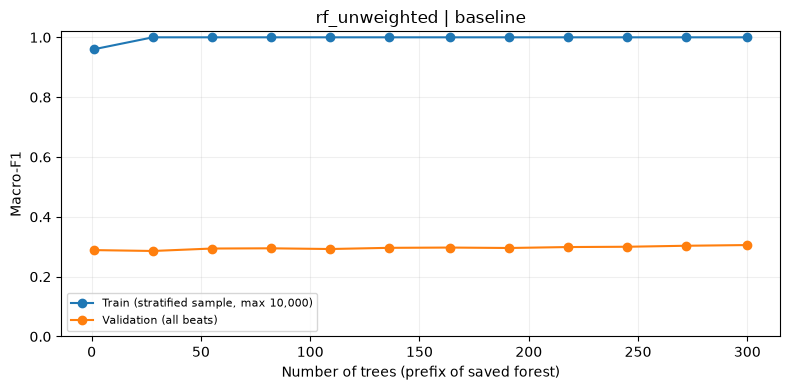

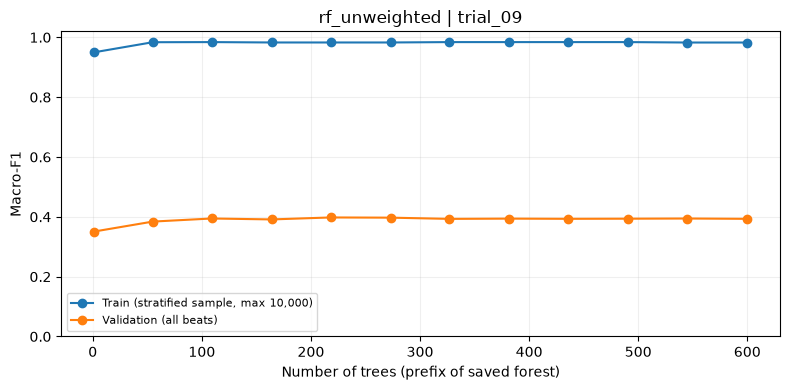

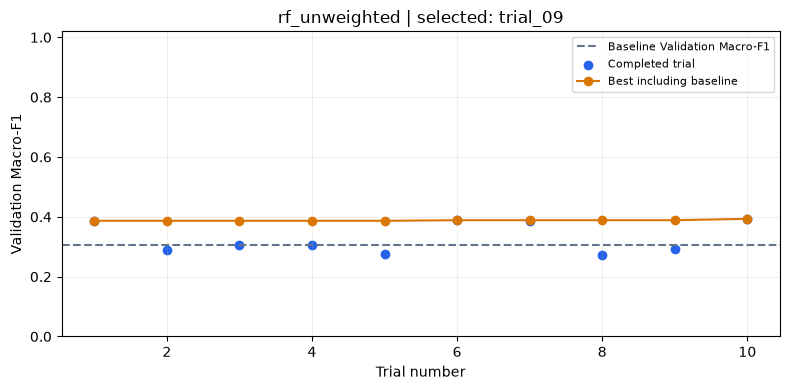

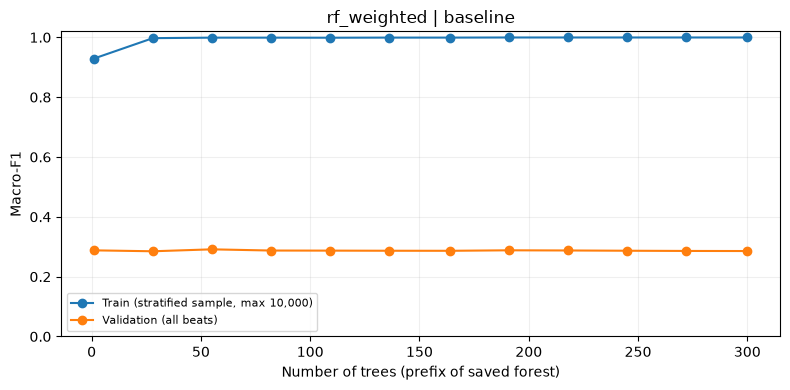

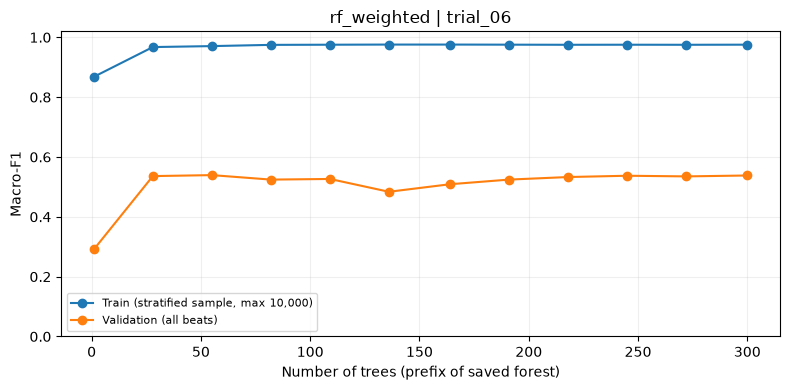

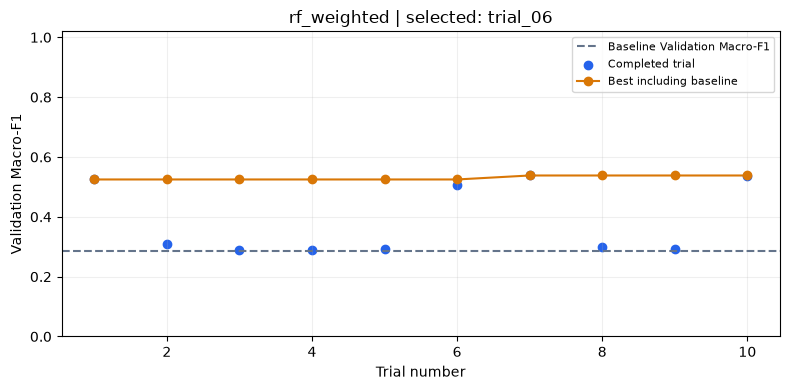

WindowsPath('C:/Users/Kongkiat/Documents/Project/cardiac-arrhythmia-classification/model/reports/training/rf')

In [18]:
# รัน cells นี้จาก artifacts เดิมได้ หลัง Imports / Configuration / helpers โดยไม่ฝึกใหม่
visual_output = reset_directory(REPORTS / 'training' / MODEL)
curve_train = load_partition('train')
curve_validation = load_partition('validation')
for weighted in WEIGHTING_OPTIONS:
    name = f'{MODEL}_{"weighted" if weighted else "unweighted"}'
    folder = ARTIFACTS / name
    selected = read_json(folder / 'selected.json')
    if selected['prepared_hash'] != sha256(DATA / 'prepared.json'):
        raise ValueError(f'{name}: ข้อมูลเปลี่ยน; รัน notebook โมเดลนี้ใหม่')
    output = visual_output / name
    output.mkdir(parents=True, exist_ok=True)
    for candidate in dict.fromkeys(['baseline', selected['candidate']]):
        run = folder / candidate
        run_output = output / candidate
        run_output.mkdir(parents=True, exist_ok=True)
        info = read_json(run / 'info.json')
        fig = plot_training_curve(run, info, run_output, curve_train, curve_validation)
        plt.show()
        plt.close(fig)
    fig = plot_tuning_progress(folder, selected, output)
    plt.show()
    plt.close(fig)
visual_output


## Final selected hyperparameters




In [19]:
from IPython.display import display

final_parameters = {}
for weighted in WEIGHTING_OPTIONS:
    name = f'{MODEL}_{"weighted" if weighted else "unweighted"}'
    folder = ARTIFACTS / name
    selected = read_json(folder / 'selected.json')
    info = read_json(folder / selected['candidate'] / 'info.json')
    values = {
        'candidate': selected['candidate'],
        'validation_macro_f1': info['validation_macro_f1'],
        **info['parameters'],
        'weighted': info['weighted'],
        'seed': info['seed'],
        'class_weights': (None if info['class_weights'] is None
                          else dict(zip(CLASSES, info['class_weights']))),
    }
    if info['batch_size'] is not None:
        values['batch_size'] = info['batch_size']
    if info['best_epoch_or_round'] is not None:
        key = 'best_epoch' if MODEL in ['cnn', 'cnn_bilstm'] else 'best_boost_round'
        values[key] = info['best_epoch_or_round']

    final_parameters[name] = {
        key: value if isinstance(value, str) else repr(value)
        for key, value in values.items()
    }

final_hyperparameters = pd.DataFrame(final_parameters)
final_hyperparameters.index.name = 'Hyperparameter / selection'
with pd.option_context('display.max_rows', None, 'display.max_columns', None,
                       'display.max_colwidth', None):
    display(final_hyperparameters)


,rf_unweighted,rf_weighted
Hyperparameter / selection,,
candidate,trial_09,trial_06
validation_macro_f1,0.3932904627698279,0.5381599191761309
n_estimators,600,300
max_depth,30,None
min_samples_leaf,2,5
max_features,0.5,0.5
weighted,False,True
seed,42,42
class_weights,None,"{'N': 0.23586988051661026, 'S': 7.575776397515528, 'V': 2.9446111398516988, 'F': 22.616953642384107, 'Q': 4.089032567049808}"
